In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
pico1 = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/src/calibration/cal_data_1.txt", sep=",")
pico1.columns = ["pico1", "Pres", "Hum"]
pico2 = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/src/calibration/cal_data_2.txt", sep=",")
pico2.columns = ["pico2", "Pres", "Hum"]
pico3 = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/src/calibration/cal_data_3.txt", sep=",")
pico3.columns = ["pico3", "Pres", "Hum"]
pico4 = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/src/calibration/cal_data_4.txt", sep=",")
pico4.columns = ["pico4", "Pres", "Hum"]
senseca = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/src/calibration/pro_line_log_20261125082527_0.csv", sep=";")
senseca = senseca.drop(columns=['Date Time'])
senseca.columns = ["senseca"]

In [16]:
print(len(pico1), len(pico2), len(pico3), len(pico4), len(senseca))

3619 3618 3608 3648 3625


In [3]:
data = pd.concat([pico1, pico2, pico3, pico4, senseca], axis=1)
data = data.drop(columns=["Pres", "Hum"])

In [32]:
data = data.groupby(np.arange(len(data)) // 10).mean()

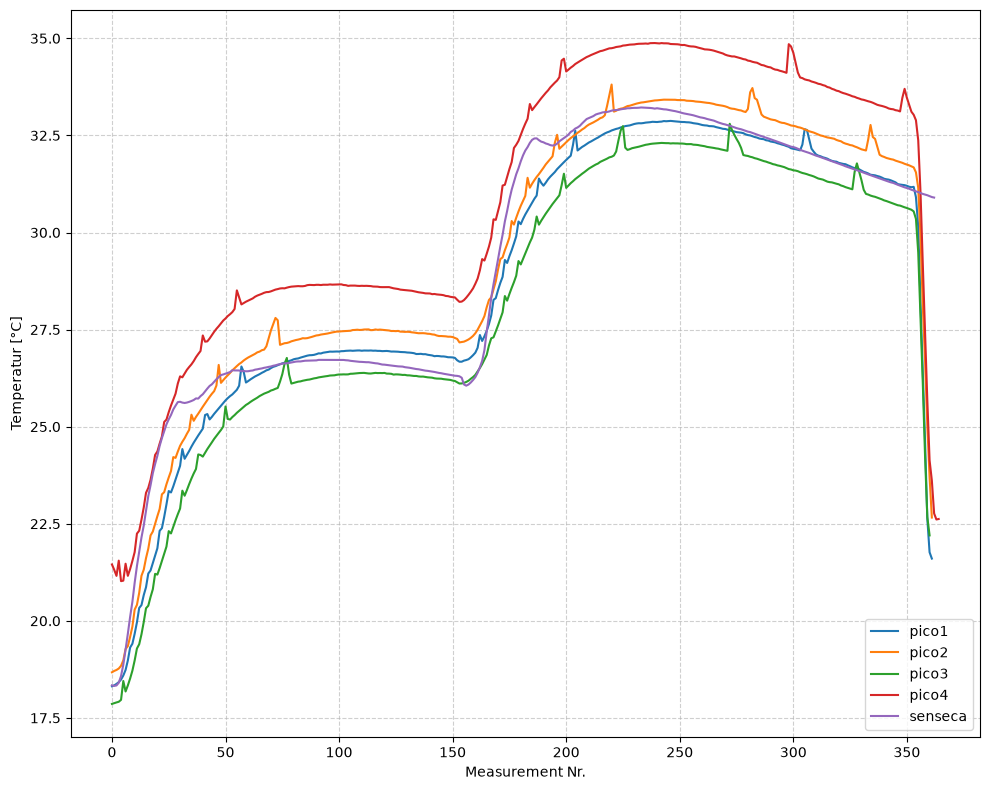

In [33]:
end = 3500
# Diagramm zeichnen
plt.figure(figsize=(10, 8))
plt.plot(data.index[:end], data[:end], label=data.columns)

# Achsen und Layout formatieren
plt.title("")
plt.xlabel("Measurement Nr.")
plt.ylabel("Temperatur [°C]")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()

plt.show()

In [40]:
diff = [data[column].to_numpy() - data["senseca"].to_numpy() for column in data.columns]

In [41]:
summary_diff = pd.DataFrame(
    data=zip(*diff),
    index=data.index,
    columns=data.columns
)

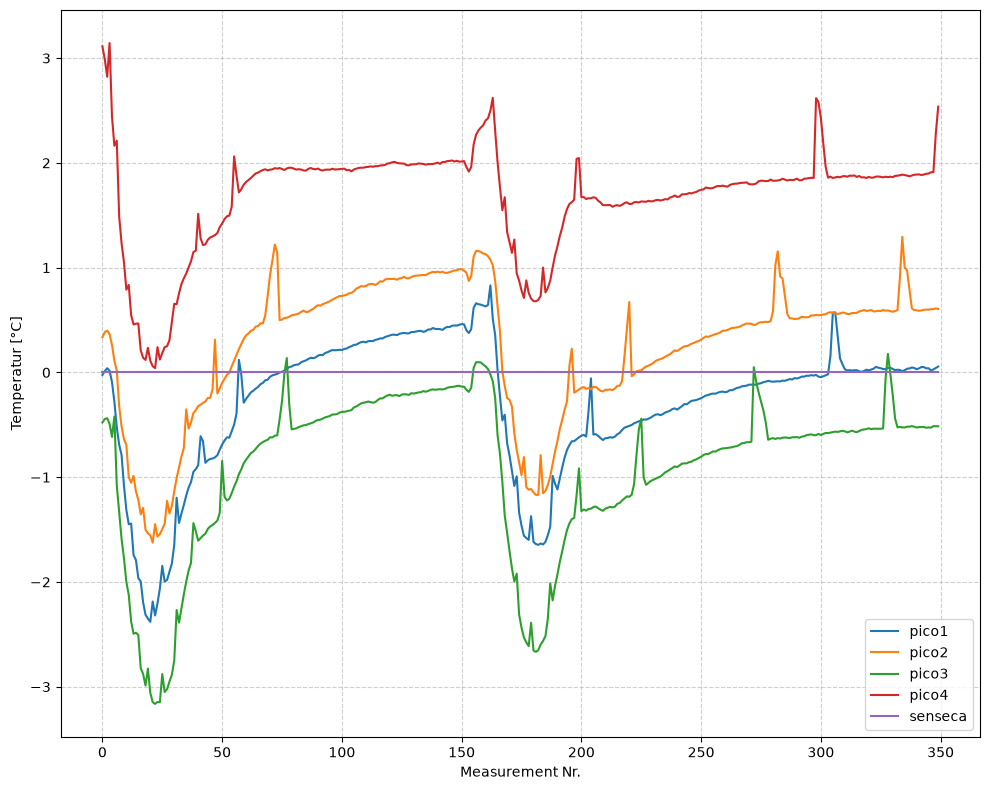

In [43]:
end = 350
# Diagramm zeichnen
plt.figure(figsize=(10, 8))
plt.plot(summary_diff[:end].index, summary_diff[:end], label=data.columns)

# Achsen und Layout formatieren
plt.title("")
plt.xlabel("Measurement Nr.")
plt.ylabel("Temperatur [°C]")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()

plt.show()

In [57]:
for column in data.columns:
    print(f"{column}: {summary_diff[column][140:150].mean().round(2)}")

print()

for column in data.columns:
    print(f"{column}: {summary_diff[column][310:320].mean().round(2)}")

pico1: 0.43
pico2: 0.96
pico3: -0.15
pico4: 2.01
senseca: 0.0

pico1: 0.02
pico2: 0.57
pico3: -0.56
pico4: 1.87
senseca: 0.0
